# What drives flight delays from New York airports?

**Question.** Which factors (time of day, airline, weather, season) are associated with
longer departure and arrival delays for flights leaving New York City?

In [1]:
%load_ext autoreload
%autoreload 2
    
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
    
from src.flights import load, add_features, mean_by, plot_ranking

plt.rcParams.update({"figure.dpi": 110})
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

In [2]:
flights = add_features(load("flights.csv.zip"))
airlines = load("airlines.csv")
weather = load("weather.csv")
print(f"{len(flights):,} flights · {flights["cancelled"].mean():.1%} cancelled")

336,776 flights · 2.5% cancelled


## Data

[nycflights](https://github.com/tidyverse/nycflights13) contains all domestic flights that departed in 2013 from New York City's airports: JFK, LaGuardia and Newark. There are tables of airlines and hourly weather at each origin airport as well. About 2.5% of flights were cancelled; delays are measured in minutes and negative values mean early departures or arrivals.

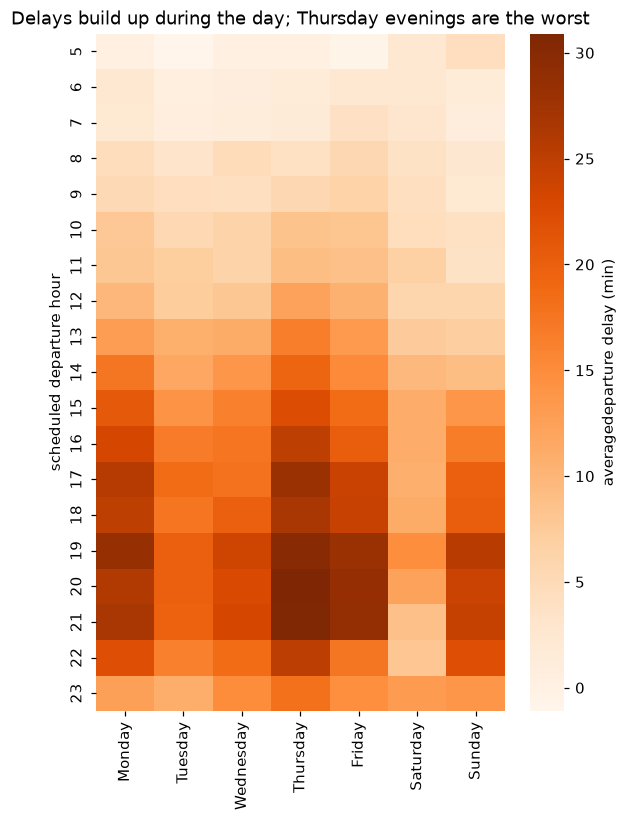

In [3]:
heat = (flights[flights["hour"] >= 5]
        .pivot_table(index="hour", columns="weekday", values="dep_delay", aggfunc="mean")
        [DAYS]
       )

fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(heat, cmap="Oranges", cbar_kws={"label": "average departure delay (min)"}, ax=ax)
ax.set(title="Delays build up during the day; Thursday evenings are the worst",
       xlabel="",
       ylabel="scheduled departure hour"
      )
ax.grid(False)
fig.savefig("../figures/delays_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()